In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.


# 05. Forecasting, churn signals, and customer value

## What this notebook does, in plain words

Forecasting means guessing a future number from past numbers. This notebook uses the simplest honest method it can defend: the average of the last three complete months. It tests that method on the past before trusting it for the future, and it reports how wrong it was. It also adds two original signals: a Recency Gap Ratio for churn risk, and a simple two year customer value estimate. Both are labelled as estimates, not facts about the future.

## The Recency Gap Ratio, the original metric of this project

Most churn rules use one fixed cutoff, for example 90 days with no order. That treats a weekly buyer and a yearly buyer the same way, which is unfair. The Recency Gap Ratio compares a customer with themselves:

  gap ratio = days since last order / median gap between that customer's own past orders.

A ratio above 2 means the customer has waited more than twice as long as usual. A ratio above 3 is a stronger warning. This needs at least two past orders, so one time buyers get no ratio, and that gap is stated, not filled in with a guess.

## The customer value estimate, and its limits

  CLV estimate (2 years) = average order value x orders per year x 2.

Orders per year uses time from first order to the reference date, 10 December 2011. This assumes the past rate continues for two more years, which it may not. It also ignores costs, discounts, and returns after the data end. Report the median, not the mean, because one very large wholesale buyer distorts the mean. Use this estimate to rank customers for care, not to book revenue.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams['figure.dpi'] = 120
ROOT = Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
RAW = ROOT / 'data' / 'raw' / 'online_retail.csv'
print('Charts folder:', CHARTS)
print('Data folder:', DATA)


Charts folder: /home/hatch/workspace/repo-builds/datanalytics-project/charts
Data folder: /home/hatch/workspace/repo-builds/datanalytics-project/data/processed


In [3]:
monthly = pd.read_csv(DATA / 'monthly_sales.csv')
complete = monthly[monthly['month'] != '2011-12'].copy()
complete['forecast'] = complete['revenue'].shift(1).rolling(3).mean()
test = complete.iloc[9:12].copy()
test['error_pct'] = (test['forecast'] - test['revenue']).abs() / test['revenue'] * 100
print(test[['month', 'revenue', 'forecast', 'error_pct']].to_string(index=False))
mape = test['error_pct'].mean()
print('Backtest MAPE, percent:', round(mape, 1))
print('MAPE means the average absolute miss, as a percent of actual sales.')
next_forecast = complete['revenue'].iloc[-3:].mean()
print('Forecast for a full December style month, pounds:', round(next_forecast, 2))
print('That forecast is the average of September, October, and November 2011.')

  month     revenue      forecast  error_pct
2011-09  952838.382 635549.533667  33.299335
2011-10 1039318.790 732757.764333  29.496342
2011-11 1161817.380 879167.024000  24.328295
Backtest MAPE, percent: 29.0
MAPE means the average absolute miss, as a percent of actual sales.
Forecast for a full December style month, pounds: 1051324.85
That forecast is the average of September, October, and November 2011.


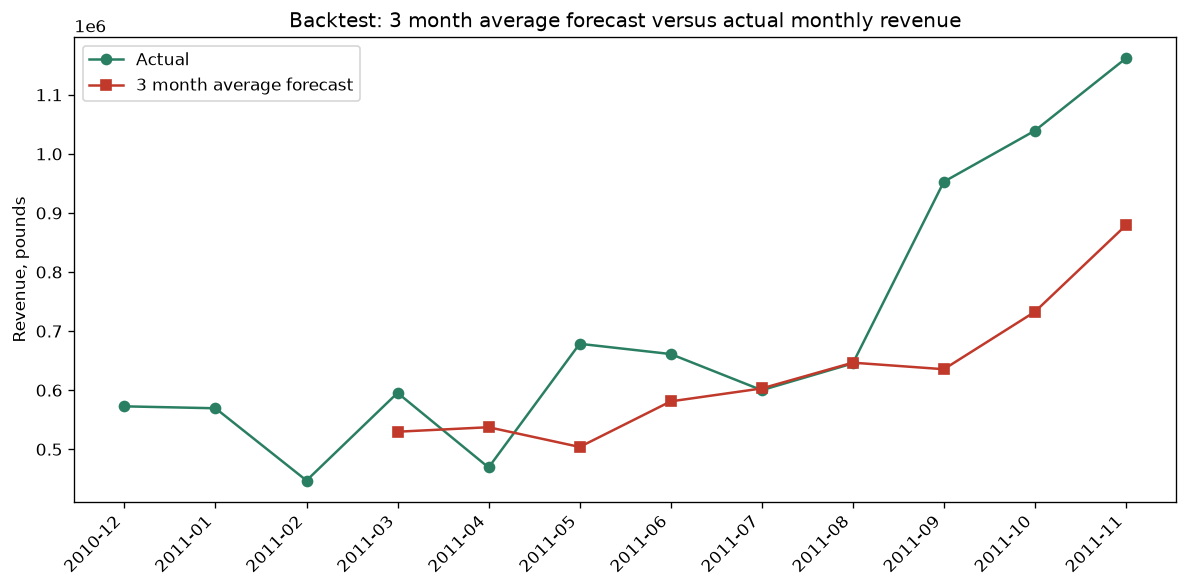

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(complete['month'], complete['revenue'], marker='o', label='Actual', color='#2a7f62')
ax.plot(complete['month'], complete['forecast'], marker='s', label='3 month average forecast', color='#c0392b')
ax.set_title('Backtest: 3 month average forecast versus actual monthly revenue')
ax.set_ylabel('Revenue, pounds')
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(CHARTS / '13_forecast_backtest.png')
plt.show()

Customers with a gap ratio: 2760 of 4338
Gap ratio above 2, percent: 18.6
Gap ratio above 3, percent: 12.2


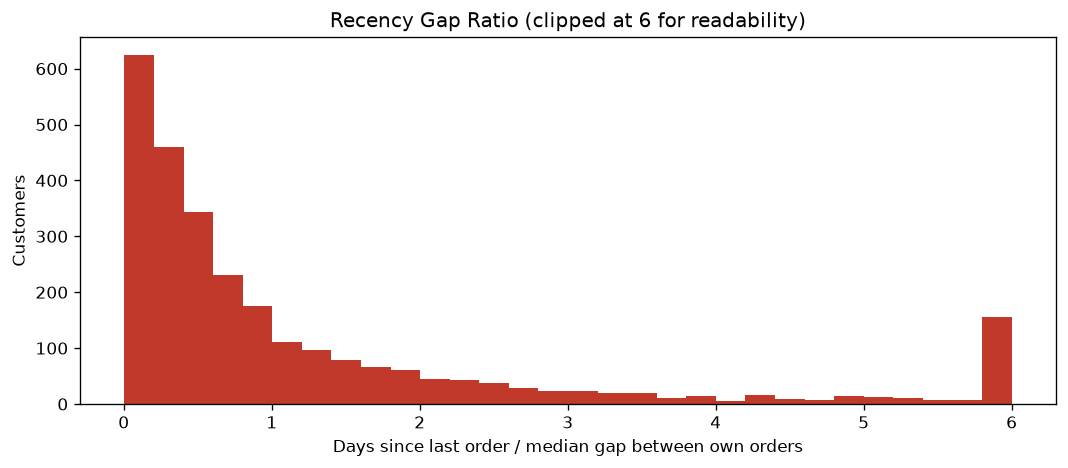

In [5]:
gap = pd.read_csv(DATA / 'customer_gap_clv.csv')
with_gap = gap.dropna(subset=['gap_ratio'])
print('Customers with a gap ratio:', len(with_gap), 'of', len(gap))
print('Gap ratio above 2, percent:', round((with_gap['gap_ratio'] > 2).mean() * 100, 1))
print('Gap ratio above 3, percent:', round((with_gap['gap_ratio'] > 3).mean() * 100, 1))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(with_gap['gap_ratio'].clip(upper=6), bins=30, color='#c0392b')
ax.set_title('Recency Gap Ratio (clipped at 6 for readability)')
ax.set_xlabel('Days since last order / median gap between own orders')
ax.set_ylabel('Customers')
plt.tight_layout()
plt.savefig(CHARTS / '14_gap_ratio.png')
plt.show()

Repeat customers: 2845
Median 2 year CLV estimate for repeat customers, pounds: 3997.7
Mean 2 year CLV estimate, pounds (distorted by outliers): 9723.01
segment
Champions              8795.247360
Loyal                  4606.854915
Recent buyers          2370.323614
At risk                2269.822782
Lost or hibernating    1679.007764
Potential loyal        1631.841022


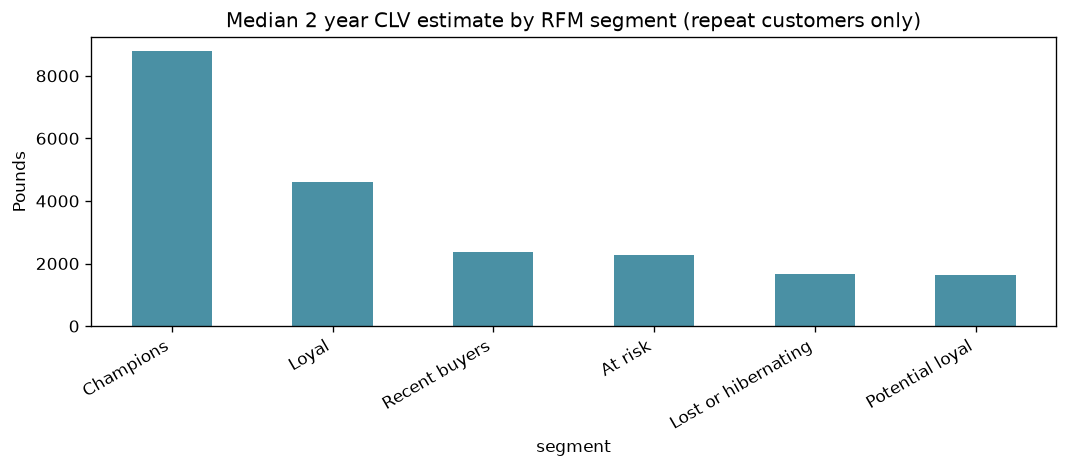

In [6]:
repeat = gap[gap['orders'] >= 2]
print('Repeat customers:', len(repeat))
print('Median 2 year CLV estimate for repeat customers, pounds:', round(repeat['clv_2yr_estimate'].median(), 2))
print('Mean 2 year CLV estimate, pounds (distorted by outliers):', round(repeat['clv_2yr_estimate'].mean(), 2))
rfm = pd.read_csv(DATA / 'rfm_segments.csv')
merged = repeat.merge(rfm[['CustomerID', 'segment']], on='CustomerID', how='left')
clv_seg = merged.groupby('segment')['clv_2yr_estimate'].median().sort_values(ascending=False)
print(clv_seg.to_string())
fig, ax = plt.subplots(figsize=(9, 4))
clv_seg.plot(kind='bar', ax=ax, color='#4a90a4')
ax.set_title('Median 2 year CLV estimate by RFM segment (repeat customers only)')
ax.set_ylabel('Pounds')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(CHARTS / '15_clv_by_segment.png')
plt.show()

## What we learned, and what not to claim

The 3 month average missed September, October, and November 2011 by 33.3, 29.5, and 24.3 percent, for an average miss (MAPE) of 29.0 percent. It always missed low, because sales were rising into autumn. That is useful information: a flat average lags a rising trend. The forecast for a full month on that method is 1,051,324.85 pounds, the average of September to November 2011. Treat that as a planning starting point, not a prediction. Do not quote it without the 29.0 percent backtest miss.

The gap signal flags 18.6 percent of customers with a usable ratio as stretched (ratio above 2), and 12.2 percent as strongly stretched (ratio above 3). A usable ratio needs at least two orders on different days, which gives 2,760 of 4,338 customers. Those customers are worth a check in first, before a discount, because a stretched wholesale buyer may simply order in bulk twice a year. The median two year value estimate for repeat customers is 3,997.70 pounds, far above the median amount already spent, because it annualises the past rate and extends it two years. That gap between spent so far and estimated future value is exactly why the formula and its limits must travel with the number.

Next: notebook 06 turns all of this into actions a small shop could actually try.